# Exploratory Data Analysis : Sales Demand Forecasting

This notebook looks at distributions, trends over time, seasonality as well as differences across stores, counties, products and customer segments.

## Setting Up

- Necessary Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels import stats
from scipy.stats import mannwhitneyu, spearmanr , kruskal, chi2_contingency
import scikit_posthocs as sp

In [2]:
# Display options
pd.set_option("display.float_format", "{:.2f}".format)
pd.set_option("display.max_columns", None)

- Datasets


In [3]:
data = "../Data/processed_data/"

branches = pd.read_csv(data + "Branches_cleaned.csv")
products = pd.read_csv(data + "Products_cleaned.csv")
customers = pd.read_csv(data + "Customers_cleaned.csv")
promos = pd.read_csv(data + "Promotions_cleaned.csv")
transactions = pd.read_csv(data + "Transactions_cleaned.csv")
receipt_lines = pd.read_csv(data + "Receipt Lines_cleaned.csv")
inflation = pd.read_csv(data + "Inflation_cleaned.csv")
holidays = pd.read_csv(data + "Holidays_cleaned.csv")
sales = pd.read_csv(data + "sales.csv")

## 1. Data Overview

- Key figures

In [4]:
total_revenue = sales["revenue_kes"].sum()
print(f"Revenue: {total_revenue}")
total_units = sales["quantity"].sum()
print(f"Units Sold: {total_units}")
total_stores = branches["store_id"].nunique()
print(f"Stores: {total_stores}")
total_products = products["product_id"].nunique()
print(f"All products: {total_products}")
total_categories = products["category"].nunique()
print(f"Product Categories: {total_categories}")
total_customers = customers["customer_id"].nunique()
print(f"Customers: {total_customers}")
start_date = transactions["transaction_date"].min()
end_date = transactions["transaction_date"].max()
print(f"Date range: {start_date} to {end_date}")

Revenue: 725492253.78
Units Sold: 4074928
Stores: 10
All products: 171
Product Categories: 9
Customers: 8222
Date range: 2024-10-01 to 2026-09-30


## 2. Distributions

### Summary Statistics

- Sales lines (revenue & quantity) and transaction basket totals

In [5]:
display(sales[["revenue_kes", "quantity"]].describe())
display(transactions["basket_total_kes"].describe())

,revenue_kes,quantity
count,2170309.00,2170309.00
mean,334.28,1.88
std,511.21,1.72
min,12.00,1.00
25%,118.00,1.00
50%,207.00,1.00
75%,379.00,2.00
max,73450.00,96.00


count   435951.00
mean      1660.70
std       2108.90
min     -15801.00
25%        480.00
50%       1098.00
75%       2180.00
max     118844.25
Name: basket_total_kes, dtype: float64

- Distribution of transaction Values

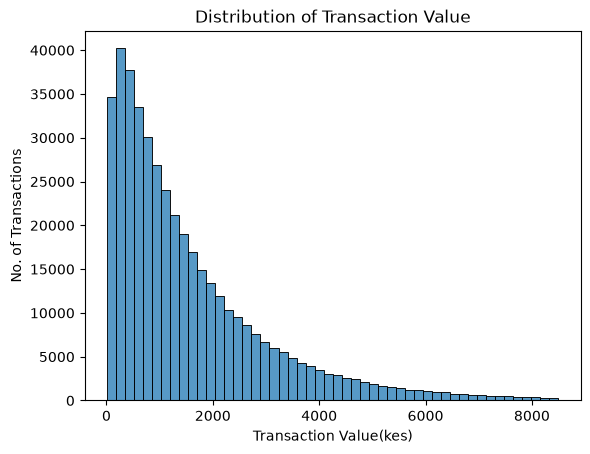

In [6]:
# Remove the negative values(returns) from the visual, and stop at the 99th percentile for readability
basket = transactions.loc[transactions["basket_total_kes"]>0, "basket_total_kes"]
basket = basket[basket <= basket.quantile(0.99)]

plt.Figure(figsize=(4,5))
sns.histplot(basket , bins = 50)
plt.title("Distribution of Transaction Value")
plt.xlabel("Transaction Value(kes)")
plt.ylabel("No. of Transactions")
plt.show()

- Distribution of quantities sold

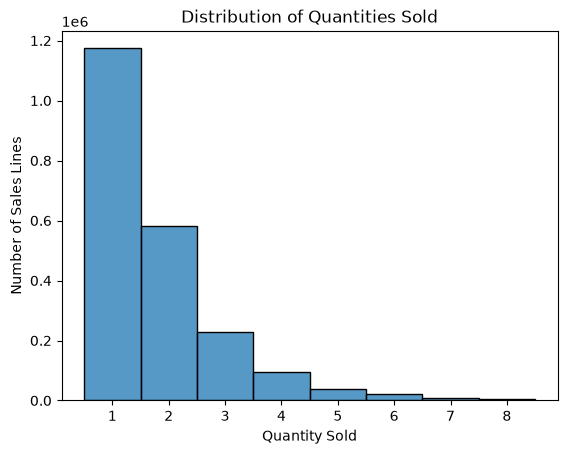

In [7]:
quantities = sales["quantity"]
quantities = quantities[quantities <= quantities.quantile(0.99)]

plt.Figure(figsize=(4,5))
sns.histplot(quantities, discrete= True)
plt.title("Distribution of Quantities Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("Number of Sales Lines")
plt.show()

_Transaction values are right-skewed: the median basket is KES 1,044 against a mean of KES 1,584, with a few very large baskets (maximum KES 113,115). Most sales lines are small: the median quantity is 1 unit and 75% of lines are 2 units or fewer, with occasional bulk purchases of up to 96 units._

## 3. Stores, Product Categories and Counties

- Revenue & Quantity Distributions across Stores

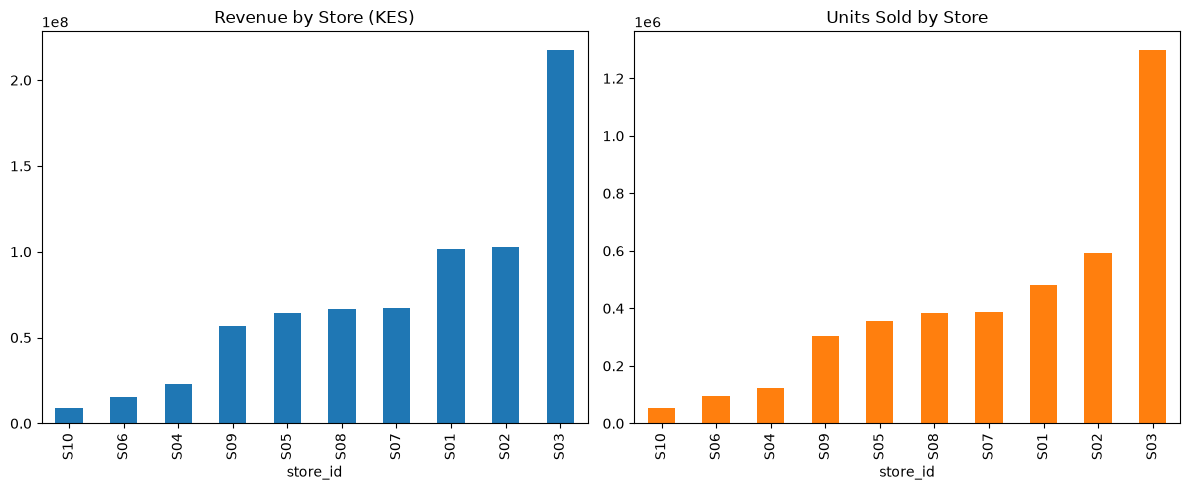

In [8]:
# Checks whether high store revenue is associated with high sales volume
store_summary = sales.groupby("store_id").agg(
    revenue = ("revenue_kes","sum"),
    quantity =("quantity", "sum")).sort_values ("revenue")
store_summary.plot(kind = "bar", subplots = True, layout = (1,2), figsize = (12,5),
                   legend = False, title = ["Revenue by Store (KES)", "Units Sold by Store"])
plt.tight_layout()
plt.show()

_An initial comparison shows that stores generating higher revenue also tend to sell more units, suggesting that sales volume is an important contributor to revenue. However, the considerable differences in performance across stores indicate that demand also varies by branch._

- Revenue and Units sold by Product Category

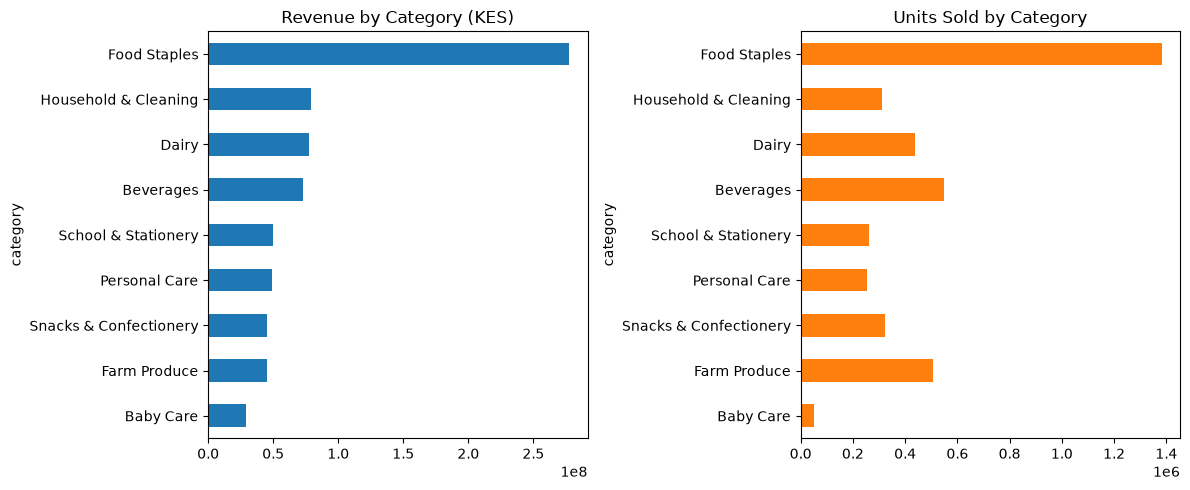

In [9]:
# To identify categories contributing the most revenue & demand
category_summary = sales.groupby("category").agg(
    revenue = ("revenue_kes","sum"),
    quantity =("quantity", "sum")).sort_values("revenue", ascending=True)

category_summary.plot(kind="barh", subplots=True, layout=(1, 2), figsize=(12, 5),
                       legend=False, sharex=False, title=["Revenue by Category (KES)", "Units Sold by Category"])
plt.tight_layout()
plt.show()

_Food Staples generates the highest revenue and records the highest quantity sold, making it the largest contributor to overall sales. Household & Cleaning, Dairy and Beverages are also major revenue contributors. Farm Produce records relatively high sales volumes despite generating lower revenue, suggesting differences in average selling prices across categories._

- Top 5 categories by revenue by store

In [10]:

# Sales by store and product category 
store_category_revenue = sales.groupby(["store_id", "category"])["revenue_kes"].sum().reset_index()
top_5_categories = store_category_revenue.sort_values(
    "revenue_kes", ascending = False).groupby("store_id").head(5)
#Ranking the categories
top_5_categories["rank"]= top_5_categories.groupby("store_id").cumcount() +1
cat_comparison = top_5_categories.pivot(
    index = "store_id",
    columns= "rank",
    values = "category")
cat_comparison.columns = ["1st", "2nd","3rd","4th","5th"]
cat_comparison

,1st,2nd,3rd,4th,5th
store_id,,,,,
S01,Food Staples,Beverages,Dairy,Household & Cleaning,Snacks & Confectionery
S02,Food Staples,Household & Cleaning,Dairy,Beverages,School & Stationery
S03,Food Staples,Household & Cleaning,Dairy,Beverages,School & Stationery
S04,Food Staples,Dairy,Beverages,Household & Cleaning,Personal Care
S05,Food Staples,Household & Cleaning,Beverages,Dairy,School & Stationery
S06,Food Staples,Dairy,Household & Cleaning,Beverages,Farm Produce
S07,Food Staples,Household & Cleaning,Dairy,Beverages,School & Stationery
S08,Food Staples,Household & Cleaning,Dairy,Beverages,School & Stationery
S09,Food Staples,Household & Cleaning,Dairy,Beverages,Personal Care


_Food Staples ranks first across all ten stores, indicating that it is consistently the largest revenue contributor. Dairy, Beverages, and Household & Cleaning also feature prominently, although their rankings vary between stores. Stores share similar core demand patterns, with some differences in their secondary categories._

- Then the top 5 products by volume for each store

In [11]:
# Units sold for each store and product
store_product_summary = sales.groupby(["store_id","product_id"]).agg(
    units_sold = ("quantity","sum"),
    revenue = ("revenue_kes", "sum")).reset_index()
# Adding the product name
store_product_summary = store_product_summary.merge(
    products[["product_id", "product_name"]],
    on="product_id")
# Getting the top 5 products and ranking them
top_5_products = store_product_summary.sort_values(
    "units_sold", ascending = False).groupby("store_id").head(5)
top_5_products["rank"]= top_5_products.groupby("store_id").cumcount() +1
prod_comparison = top_5_products.pivot(
    index = "store_id",
    columns= "rank",
    values = "product_name")
prod_comparison.columns = ["1st", "2nd","3rd","4th","5th"]
prod_comparison

,1st,2nd,3rd,4th,5th
store_id,,,,,
S01,Sugar 1kg,Tomatoes 1kg,Sliced White Bread 400g,Sliced White Bread 400g,Onions 1kg
S02,Maize Flour 2kg,Sugar 1kg,Fresh Milk 500ml,Soda 500ml,Tomatoes 1kg
S03,Maize Flour 2kg,Fresh Milk 500ml,Sugar 1kg,Tomatoes 1kg,Sliced White Bread 400g
S04,Sugar 1kg,Tomatoes 1kg,Sliced White Bread 400g,Sliced White Bread 400g,Onions 1kg
S05,Sugar 1kg,Tomatoes 1kg,Sliced White Bread 400g,Kale Bunch,Bottled Water 1.5L
S06,Sugar 1kg,Sliced White Bread 400g,Tomatoes 1kg,Kale Bunch,Maize Flour 2kg
S07,Maize Flour 2kg,Sugar 1kg,Soda 500ml,Fresh Milk 500ml,Sliced White Bread 400g
S08,Maize Flour 2kg,Sugar 1kg,Soda 500ml,Tomatoes 1kg,Fresh Milk 500ml
S09,Sugar 1kg,Tomatoes 1kg,Sliced White Bread 400g,Kale Bunch,Bottled Water 1.5L


_Sugar 1kg, Maize Flour 2kg and Tomatoes 1kg frequently rank among the top-selling products across stores. Sliced White Bread 400g also features consistently in the top five. This suggests strong demand for essential food products across branches, although the ranking of individual products varies by store._

- Payment methods across stores

In [12]:
# Payment method share per store
payment_method_share = transactions.merge(branches[["store_id", "store_name", "store_positioning"]], on="store_id")

payment_method_share = pd.crosstab(
    [payment_method_share["store_id"], payment_method_share["store_name"], payment_method_share["store_positioning"]],
    payment_method_share["payment_method"], normalize="index") * 100
display(payment_method_share.round(2))

,,payment_method,Card,Cash,M-Pesa,unknown
store_id,store_name,store_positioning,,,,
S01,Kilimani Supermarket,Upmarket,26.36,26.72,46.89,0.04
S02,Eastleigh Supermarket,Value,13.98,31.17,54.81,0.04
S03,Embakasi Hypermarket,Value,16.86,29.93,53.19,0.03
S04,Karen Express,Upmarket,27.69,27.30,44.97,0.04
S05,Ruiru Supermarket,Mid-market,19.80,26.62,53.10,0.48
S06,Kikuyu Express,Mid-market,18.33,31.41,50.20,0.06
S07,Thika Supermarket,Value,15.44,30.20,54.33,0.04
S08,Athi River Supermarket,Value,16.96,29.26,53.74,0.04
S09,Ongata Rongai Supermarket,Mid-market,19.63,28.22,52.12,0.03


_M-Pesa is the most common payment method at every store (45-55% of transactions), followed by cash (27-33%) and card (14-28%). Card use is highest at the upmarket stores, Karen Express (27.69%) and Kilimani (26.36%), and lowest at the value stores such as Eastleigh (13.98%) and Thika (15.44%), where M-Pesa is strongest at 53-55%. Cash is the most stable method across stores_

In [13]:
# Retrieving positioning and payment info
payment_data = transactions.merge(
    branches[['store_id', 'store_positioning']],
    on='store_id', how='left')
# excluding unknown values
payment_data = payment_data[
    (payment_data['store_positioning'].str.lower() != 'unknown') &
    (payment_data['payment_method'].str.lower() != 'unknown')]

In [14]:
# Categorical independent variables being investigated therefore Chi 2 test of independence used
contingency_table = pd.crosstab(payment_data["store_positioning"], payment_data["payment_method"])

# To understand the relationship between payment method and store positioning and if there is any
H0 = "Payment method and store positioning are independent"
H1 = "Payment method and store positioning are associated."
α = 0.05
chi2, p, dof, expected = chi2_contingency(contingency_table)

print("Chi-square statistic:", chi2)
print("P-value:", p)
print("Degrees of freedom:", dof)
print("Expected frequencies:\n", expected)

if p <= α:
 print("Reject the null Hypothesis: Payment method and store positioning are associated")
else:
 print("Fail to reject the null hypothesis: There is no association between parment method and store positioning") 

Chi-square statistic: 4656.551491152214
P-value: 0.0
Degrees of freedom: 4
Expected frequencies:
 [[ 19295.434893    30146.56891549  53810.99619151]
 [ 14509.55857357  22669.26917673  40464.17224969]
 [ 47599.00653343  74367.16190778 132743.83155879]]
Reject the null Hypothesis: Payment method and store positioning are associated


In [15]:
# Effect Size Test
n = contingency_table.sum().sum()
r, k = contingency_table.shape
cramers_v = np.sqrt(chi2 / (n * min(r - 1, k - 1)))

print(f"Effect size (Cramér's V): {cramers_v:.2f}")

Effect size (Cramér's V): 0.07


_The Chi-square test indicated a statistically significant association between payment method and store positioning (χ² = 4656.55, df = 4, p < 0.001). However, Cramér's V (0.073) indicated a very weak association, suggesting that store positioning has little association with customers' payment method choices._

- Sales Performance Across Counties

In [16]:
# Adding county data to sales
county_sales = sales.merge(branches[["store_id", "county"]],on="store_id")

county_summary = county_sales.groupby("county").agg(
    revenue=("revenue_kes", "sum"),
    units_sold=("quantity", "sum"),
    transactions=("transaction_id", "nunique"),
    stores=("store_id", "nunique"))
# Per-store averages
county_summary["avg_revenue_per_store"] = county_summary["revenue"] / county_summary["stores"]
county_summary["avg_units_per_store"] = county_summary["units_sold"] / county_summary["stores"]
county_summary["avg_transactions_per_store"] = county_summary["transactions"] / county_summary["stores"]
county_summary["avg_transaction_value"] = (county_summary["revenue"] / county_summary["transactions"])

display(county_summary.sort_values("revenue", ascending=False))

,revenue,units_sold,transactions,stores,avg_revenue_per_store,avg_units_per_store,avg_transactions_per_store,avg_transaction_value
county,,,,,,,,
Nairobi,445148103.50,2495671,246952,4,111287025.88,623917.75,61738.00,1802.57
Kiambu,147591390.61,837996,98308,3,49197130.20,279332.00,32769.33,1501.32
Machakos,66666838.01,382168,40252,1,66666838.01,382168.00,40252.00,1656.24
Kajiado,56939278.65,304713,36176,1,56939278.65,304713.00,36176.00,1573.95
Nakuru,9146643.01,54380,9064,1,9146643.01,54380.00,9064.00,1009.12


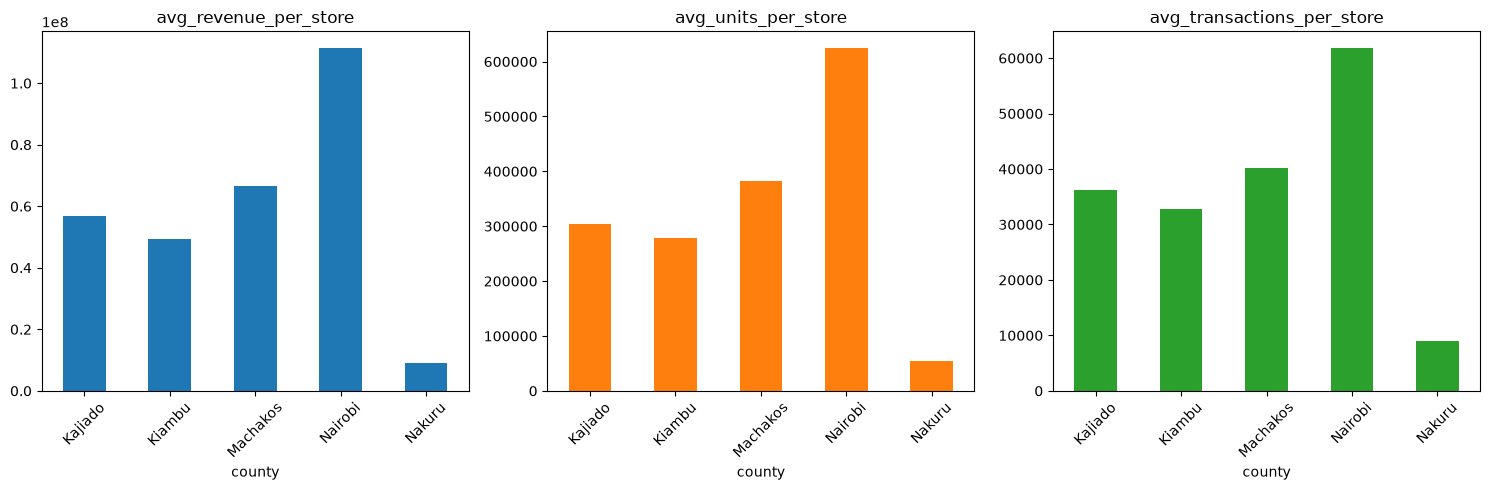

In [17]:
county_summary[["avg_revenue_per_store", "avg_units_per_store",
    "avg_transactions_per_store"]].plot(
    kind="bar", subplots=True, layout=(1, 3), figsize=(15, 5), legend=False, rot=45)
plt.tight_layout()
plt.show()

_Nairobi recorded the highest total revenue and sales volume, partly reflecting its 4 stores, and also the highest average revenue per store (about KES 104M). Despite having three stores and higher total units sold than Machakos and Kajiado, Kiambu recorded lower average revenue per store. Machakos and Kajiado had higher average transaction values (KES 1,596 and KES 1,557, respectively) than Kiambu (KES 1,476), which may explain the difference in revenue. Nakuru, with one store, recorded by far the lowest revenue (KES 9.3M) and average transaction value (KES 1,021)._

## 4. Customer Segments

- - Customer distribution by age and gender

In [18]:
# Adding age band and gender to sales lines
customer_sales = sales.merge(
    transactions[["transaction_id", "customer_id"]], on="transaction_id").merge(
    customers[["customer_id", "age_band", "gender"]], on="customer_id")

# Leaving out "unknown" values in either
customer_sales = customer_sales[(customer_sales["age_band"] != "unknown") &
    (customer_sales["gender"] != "unknown")]

- Revenue and Units sold by age band and gender

In [19]:
# Customer Summary
customer_summary = customer_sales.groupby(["age_band", "gender"]).agg(
    customers=("customer_id", "nunique"),
    revenue=("revenue_kes", "sum"),
    units_sold=("quantity", "sum"))

#Average per customer
customer_summary["avg_revenue"] = (customer_summary["revenue"] / customer_summary["customers"])
customer_summary["avg_units"] = (customer_summary["units_sold"] / customer_summary["customers"])

display(customer_summary)

customers     revenue  units_sold  avg_revenue  avg_units
age_band gender                                                           
18-24    Female        458 14063482.20       81384     30706.29     177.69
         Male          333 11574515.59       68372     34758.31     205.32
25-34    Female       1202 51892839.06      291193     43172.08     242.26
         Male          870 39035958.22      217982     44868.92     250.55
35-44    Female       1001 51425514.11      287149     51374.14     286.86
         Male          678 36735588.00      203804     54182.28     300.60
45-54    Female        691 36033653.87      198862     52147.11     287.79
         Male          559 25751848.83      144916     46067.71     259.24
55+      Female        572 22437971.46      128509     39227.22     224.67
         Male          408 16925736.25       96624     41484.65     236.82

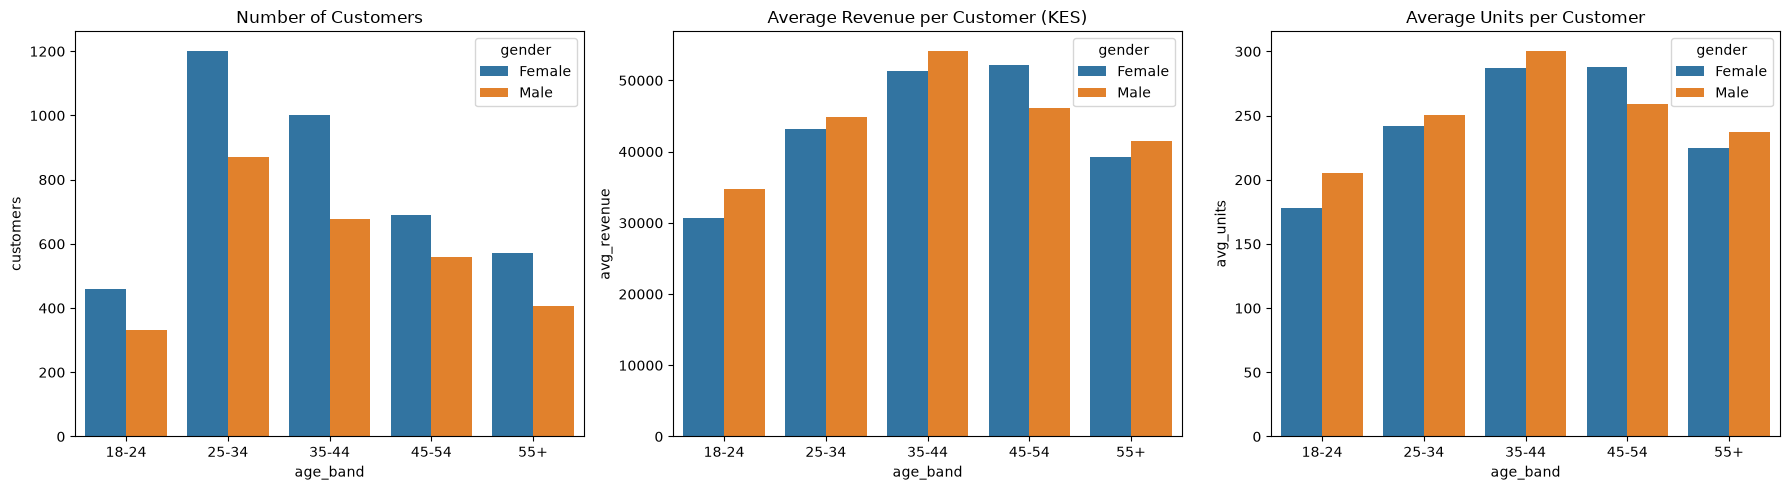

In [20]:
segments = customer_summary.reset_index()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(data=segments, x="age_band", y="customers", hue="gender", ax=axes[0])
axes[0].set_title("Number of Customers")

sns.barplot(data=segments, x="age_band", y="avg_revenue", hue="gender", ax=axes[1])
axes[1].set_title("Average Revenue per Customer (KES)")

sns.barplot(data=segments, x="age_band", y="avg_units", hue="gender", ax=axes[2])
axes[2].set_title("Average Units per Customer")

plt.tight_layout()
plt.show()

- Customer Purchase Frequency

In [21]:
# Transactions per customer
customer_frequency = customer_sales.groupby(["customer_id", "age_band", "gender"]).agg(
    transactions=("transaction_id", "nunique")).reset_index()
# identifying repeat customers
customer_frequency["repeat_customer"] = (customer_frequency["transactions"] > 1)
display(customer_frequency["repeat_customer"].value_counts(normalize=True) * 100)

repeat_customer
True    70.79
False   29.21
Name: proportion, dtype: float64

_Most customers fall in the 25-34 and 35-44 age bands, and there are more female than male customers in every band. Customers aged 35-44 record the highest average revenue and units sold per customer overall. Male customers have higher averages in most age groups, except among those aged 45-54, where female customers record higher averages. About 70% of customers bought more than once and the rest bought only once_

## 5. Trends over time and Seasonality

Examines how sales change over time and whether recurring patterns occur across different months, weekdays, month-end periods and public holidays. 

The differences between groups are tested at the 5% significance level.   
Because there are thousands of rows, almost any difference comes out "significant", so every test is paired with an **effect size** that shows how big the difference is.   
For two groups we use the rank-biserial correlation (about 0.1 is small, 0.3 medium, 0.5 large; a positive value means the first group listed is higher).

- Daily Sales Table

In [22]:
daily_sales = sales.groupby("transaction_date").agg(
    revenue=("revenue_kes", "sum"),
    units_sold=("quantity", "sum"),
    transactions=("transaction_id", "nunique"),
    end_month=("end_month", "max"),
    is_holiday=("is_holiday", "max")).reset_index()

daily_sales["transaction_date"] = pd.to_datetime(daily_sales["transaction_date"])
daily_sales["month"] = daily_sales["transaction_date"].dt.month
daily_sales["day_name"] = daily_sales["transaction_date"].dt.day_name()

- - Average daily sales by weekday

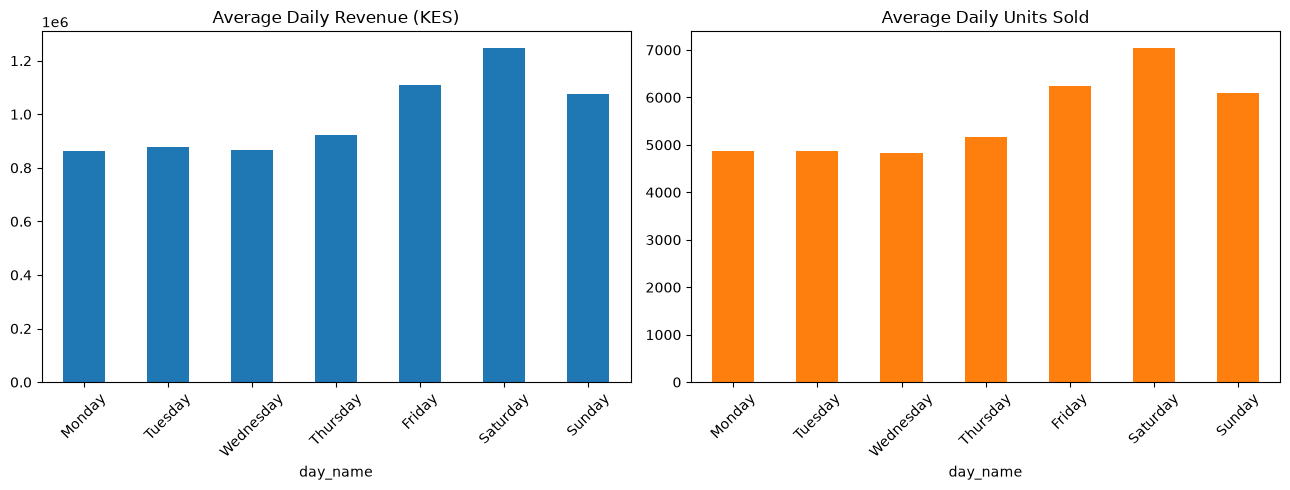

In [23]:
weekdays = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_sales = daily_sales.groupby("day_name")[["revenue", "units_sold"]].mean().reindex(weekdays)

weekday_sales.plot(kind="bar", subplots=True, layout=(1, 2), figsize=(13, 5), legend=False, rot=45,
                   title=["Average Daily Revenue (KES)", "Average Daily Units Sold"])
plt.tight_layout()
plt.show()

_The results indicate stronger demand towards the weekend, as average daily revenue and units sold are highest on Saturdays, followed by Sundays and Fridays. Sales are generally lower from Monday to Thursday, with Thursday showing a slight increase._

- Weekly Trend - Busy and quiet periods across the 2 years

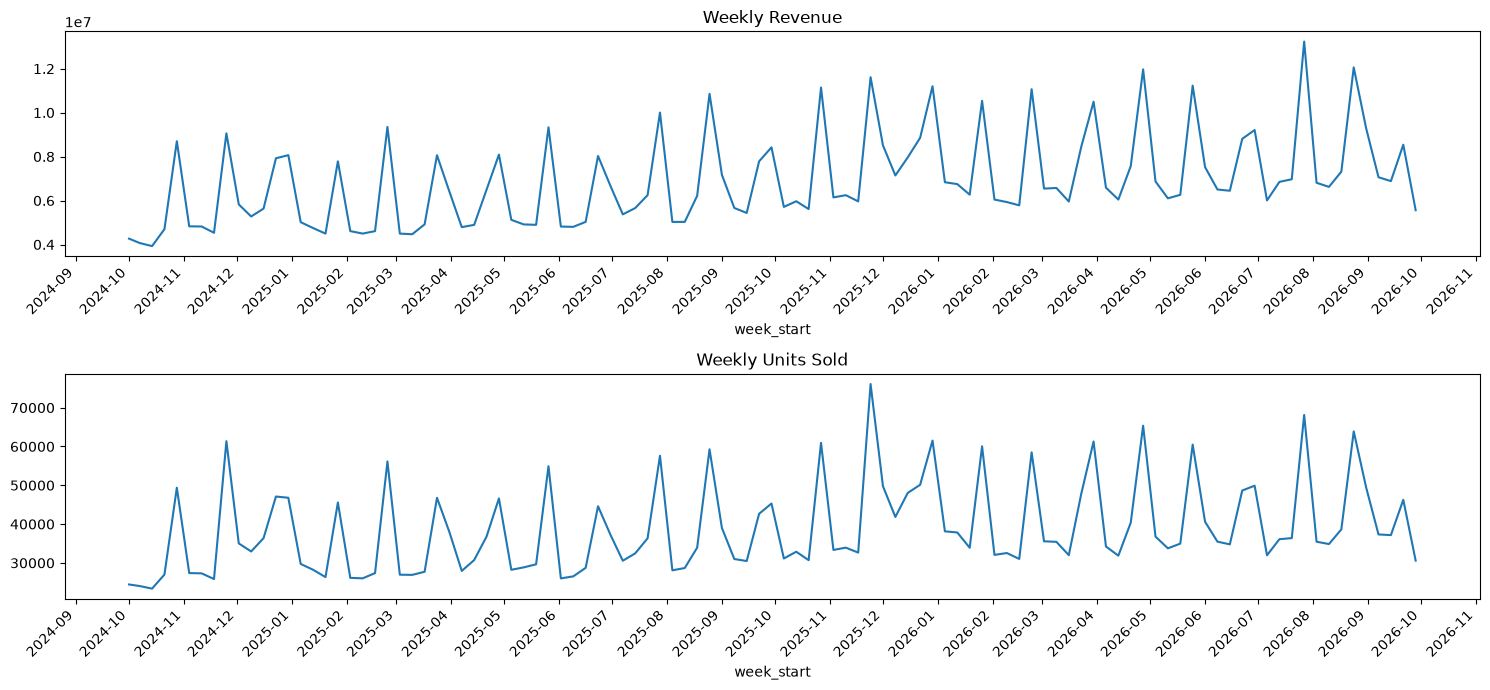

In [24]:
sales["week_start"] = pd.to_datetime(sales["week_start"])
weekly_sales = sales.groupby("week_start").agg(
    revenue = ("revenue_kes","sum"),
    units_sold = ("quantity","sum"))
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
weekly_sales["revenue"].plot(ax=axes[0], title="Weekly Revenue")
weekly_sales["units_sold"].plot(ax=axes[1], title="Weekly Units Sold")

for ax in axes:
    ax.xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator())
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

_Weekly revenue and units sold fluctuate throughout the period, with noticeable increases around some month-end weeks. The weekly trends also show variations in demand over time._

- Monthly trend

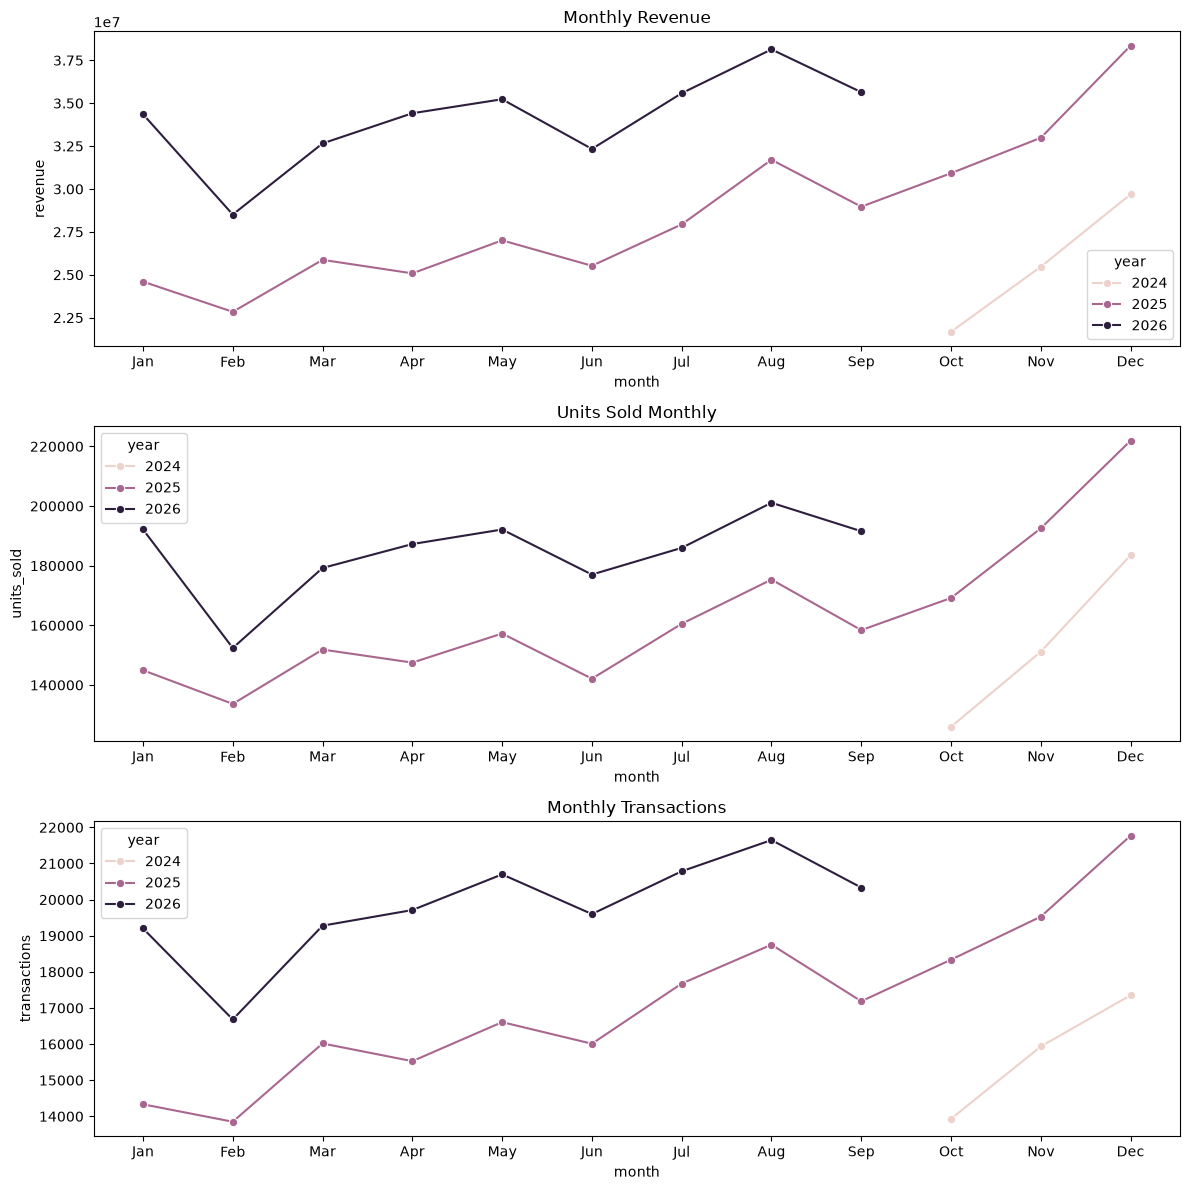

In [25]:
# Monthly revenue, units sold and transaction volumes by year.
monthly_sales = sales.groupby(["year","month"]).agg(
    revenue = ("revenue_kes","sum"),
    units_sold = ("quantity","sum"),
    transactions = ("transaction_id", "nunique")).reset_index()
# Visual comparison
fig, axes = plt.subplots(3, 1, figsize=(12, 12))
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
measures = ["revenue", "units_sold","transactions"]
titles = ["Monthly Revenue","Units Sold Monthly", "Monthly Transactions"]
for i in range(3):
    sns.lineplot(data = monthly_sales, x ="month", y = measures[i], 
                 hue = "year", marker="o", ax= axes[i])

    axes[i].set_title(titles[i])
    axes[i].set_xticks(range(1, 13))
    axes[i].set_xticklabels(month_names) 
plt.tight_layout()
plt.show()

_Monthly revenue, units sold and transaction volumes generally increase across the period, although there are some month-to-month fluctuations. December records high sales in both years, followed by a decline in January and February._

- - Finding out whether the 12 months sales differ (Kruskal Wallis)

In [26]:
# Revenue & units sold have a skewed distribution due to outliers
# There are more than 2 independent groups(12months) hence the choice of the non parametric Kruskal Wallis
daily_sales["month"] = pd.to_datetime(daily_sales["transaction_date"]).dt.month

H0 = "Daily revenue (or unis sold) has the same distribution accross the 12 months"
H1 = "At least one month has a different distribution of daily revenue (or units sold)."

α = 0.05
revenue_by_month = []
units_by_month = []

revenue_by_month = [daily_sales[daily_sales["month"] == month]["revenue"] for month in range(1, 13)]
units_by_month = [daily_sales[daily_sales["month"] == month]["units_sold"] for month in range(1, 13)]

revenue_stat, revenue_p = kruskal(*revenue_by_month)
units_stat, units_p = kruskal(*units_by_month)

print(f"{'Revenue':<15} H Statistic = {revenue_stat:>15,.2f}   p = {revenue_p:.4g}")
print(f"{'Units Sold':<15}H Statistic = {units_stat:>15,.2f}   p = {units_p:.4g}")

if revenue_p <= α :
    print("Reject H0: At least one calendar month has a statistically significant difference in daily revenue.")
else:
    print("Fail to reject H0: There is no statistically significant difference in daily revenue across the calendar months.")

if units_p <= α :
    print("Reject H0: At least one calendar month has a statistically significant difference in daily units sold.")
else:
    print("Fail to reject H0: There is no statistically significant difference in daily units sold across the calendar months.")

Revenue         H Statistic =           34.31   p = 0.0003217
Units Sold     H Statistic =           38.88   p = 5.551e-05
Reject H0: At least one calendar month has a statistically significant difference in daily revenue.
Reject H0: At least one calendar month has a statistically significant difference in daily units sold.


In [27]:
# Effect size test (epsilon test)
k = 12 # No. of groups i.e months
n = 730 # Observations

revenue_effect_size = (revenue_stat - 12 + 1) / (n - k)
units_sold_effect_size = (units_stat - 12 + 1) / (n - k)

print(f"Epsilon Effect_size: Revenue: {revenue_effect_size:.3f}")
print(f"Epsilon Effect_size: Units_sold: {units_sold_effect_size:.3f}")

Epsilon Effect_size: Revenue: 0.032
Epsilon Effect_size: Units_sold: 0.039


_The Kruskal Wallis tests identified statistically significant differences in daily revenue and units sold across calendar months (p < 0.001 for both). However, the epsilon-squared values of 0.034 for revenue and 0.040 for units sold indicate small effect sizes. This suggests that while sales patterns vary across months, the magnitude of these differences is relatively small._

In [28]:
# To determine the months with differences in daily typical units sold/revenue:
# Visual comparison of the medians
monthly_summary = daily_sales.groupby("month").agg(
    revenue_median=("revenue", "median"),
    units_median=("units_sold", "median"))
display(monthly_summary)

,revenue_median,units_median
month,,
1,884725.10,5083.50
2,790704.90,4350.00
3,795294.32,4225.50
4,879016.32,4615.00
5,890604.51,5010.00
6,858336.50,4684.00
7,929781.10,4930.50
8,925475.40,4985.50
9,952967.57,5150.50


In [29]:
# Using dunn's post hoc test
revenue_posthoc = sp.posthoc_dunn(daily_sales, val_col="revenue", group_col="month", p_adjust="bonferroni")
units_posthoc = sp.posthoc_dunn(daily_sales, val_col="units_sold",group_col="month",p_adjust="bonferroni")

print(f"Revenue post-hoc results:{display(revenue_posthoc)}")
print(f"Units sold post-hoc results: {display(units_posthoc)}")


,1,2,3,4,5,6,7,8,9,10,11,12
1,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
2,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.31,0.52,1.00,1.00,0.25
3,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.40,0.68,1.00,1.00,0.32
4,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
5,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.68,1.00,1.00
6,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
7,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.08,1.00,1.00
8,1.00,0.31,0.40,1.00,1.00,1.00,1.00,1.00,1.00,0.01,1.00,1.00
9,1.00,0.52,0.68,1.00,1.00,1.00,1.00,1.00,1.00,0.01,1.00,1.00
10,1.00,1.00,1.00,1.00,0.68,1.00,0.08,0.01,0.01,1.00,1.00,0.01


Revenue post-hoc results:None


,1,2,3,4,5,6,7,8,9,10,11,12
1,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.74
2,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.90,1.00,1.00,1.00,0.00
3,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.01
4,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.72
5,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.42,1.00,1.00
6,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.10
7,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.22,1.00,1.00
8,1.00,0.90,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.05,1.00,1.00
9,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.07,1.00,1.00
10,1.00,1.00,1.00,1.00,0.42,1.00,0.22,0.05,0.07,1.00,1.00,0.00


Units sold post-hoc results: None


_The post-hoc test identified significant differences in daily revenue between October and August, September and December, with October recording lower median revenue. For units sold, December recorded significantly higher median sales than February, March, October and November. August also recorded higher median units sold than October. No significant differences were found in the remaining month comparisons._

- Month end vs non month end sales

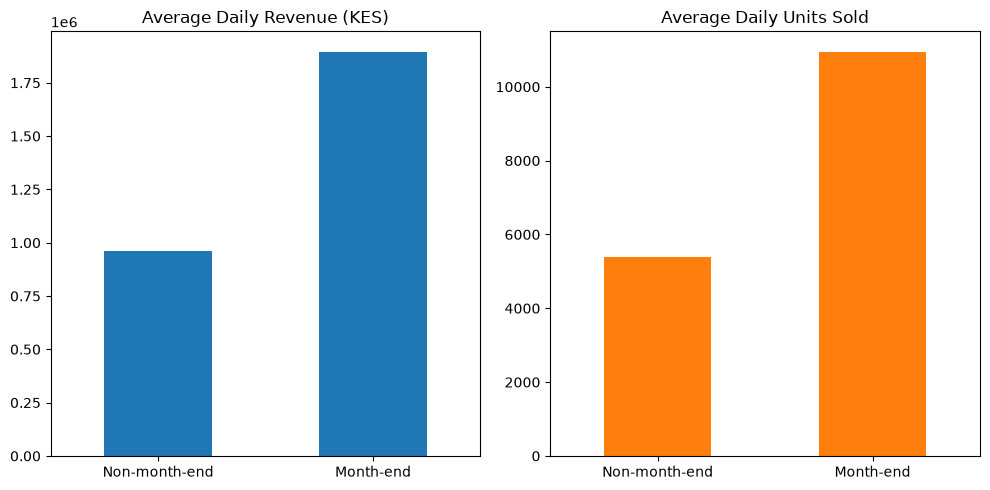

In [30]:
month_end_sales = daily_sales.groupby("end_month")[["revenue", "units_sold"]].mean()
month_end_sales.index = ["Non-month-end", "Month-end"]

month_end_sales.plot(kind="bar", subplots=True, layout=(1, 2), figsize=(10, 5), 
                     legend=False, rot=0, title=["Average Daily Revenue (KES)", "Average Daily Units Sold"])
plt.tight_layout()
plt.show()

_Month-end days recorded substantially higher average daily revenue and units sold compared to non-month-end days, suggesting a strong increase in sales towards the end of the month, possibly reflecting payday-related spending._

- - Mannwhitneyu test

In [31]:
# Revenue and units sold are right skewed, as they contain extremely high values.
# There are 2 groups(month end and non month end) hence the choice of non parametric mannwhitneyu test
H0 = "There is no statistically significant difference between month-end and non-month-end days."
H1 = "There is a statistically significant difference between month-end and non-month-end days."

month_end = daily_sales[daily_sales["end_month"]==True]
non_month_end = daily_sales[daily_sales["end_month"]==False]

α = 0.05
revenue_stat, revenue_p = mannwhitneyu(month_end["revenue"], non_month_end["revenue"], alternative="two-sided")
units_stat, units_p = mannwhitneyu(month_end["units_sold"], non_month_end["units_sold"],alternative="two-sided")

print(f"{'Revenue':<15} U Statistic = {revenue_stat:>15,.2f}   p = {revenue_p:.4g}")
print(f"{'Units Sold':<15}U Statistic = {units_stat:>15,.2f}   p = {units_p:.4g}")

if revenue_p <= α:
    print("Reject H0: There is a significant difference in daily revenue between month-end and non-month-end days.")
else:
    print("Fail to reject H0: There is no significant difference in daily revenue between month-end and non-month-end days.")

if units_p <= α :
    print("Reject H0: There is a significant difference in daily units sold between month-end and non-month-end days.")
else:
    print("Fail to reject H0: There is no significant difference in daily units sold between month-end and non-month-end days.")


Revenue         U Statistic =       16,134.00   p = 4.658e-14
Units Sold     U Statistic =       16,206.00   p = 2.698e-14
Reject H0: There is a significant difference in daily revenue between month-end and non-month-end days.
Reject H0: There is a significant difference in daily units sold between month-end and non-month-end days.


In [32]:
# Effect Sizes
n1 = len(month_end)
n2 = len(non_month_end)

revenue_effect = 2 * revenue_stat/ (n1 * n2) - 1
units_effect = 2 * units_stat/ (n1 * n2) - 1

print(f"Revenue effect size: {revenue_effect:.3f}")
print(f"Units sold effect size: {units_effect:.3f}")

Revenue effect size: 0.904
Units sold effect size: 0.913


_The Mann–Whitney U tests identified statistically significant differences in daily revenue and units sold between month-end and non-month-end days (p < 0.001 for both). The rank-biserial correlations of -0.906 for revenue and -0.914 for units sold indicate very large differences between the two groups. This suggests that month-end is strongly associated with higher daily sales and may be a useful feature to include in the forecasting model._

- Average holiday vs ordinary days

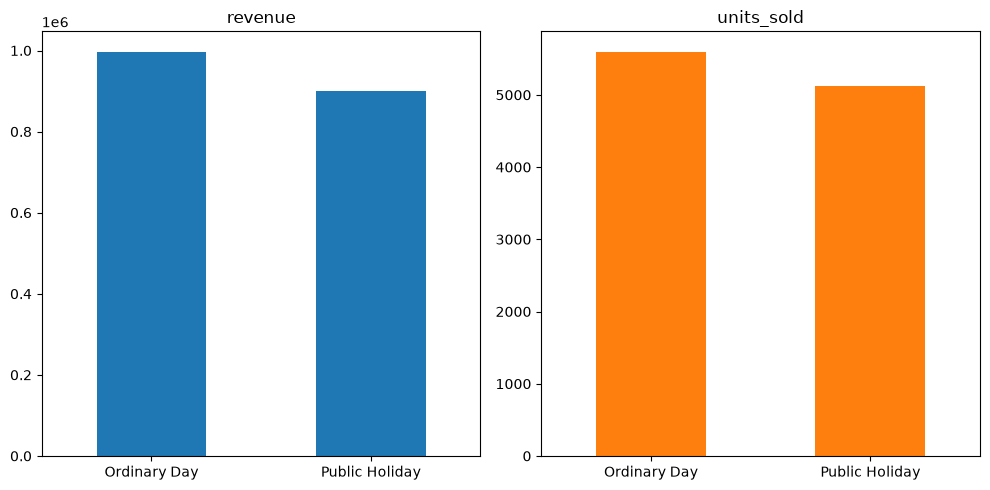

In [33]:
holiday_sales = daily_sales.groupby("is_holiday")[["revenue", "units_sold"]].mean()
holiday_sales.index = ["Ordinary Day", "Public Holiday"]
holiday_sales.plot(kind="bar", subplots=True, layout=(1, 2),
                   figsize=(10, 5), legend=False, rot=0)
plt.tight_layout()
plt.show()

_Public holidays recorded lower average daily revenue and fewer units sold than ordinary days. This suggests that sales demand was lower on public holidays during the period analysed._

- - Mannwhitney u test

In [34]:
# Units sold and revenue have a right skewed distribution, and are right skewed. Since there are 2 groups, holidays and ordinary days, mannwhitneyu test is most appropriate
H0 = "There is no statistically significant difference in daily revenue (or units sold) between public holidays and ordinary days."
H1 = "There is a statistically significant difference in daily revenue (or units sold) between public holidays and ordinary days."

holiday = daily_sales[daily_sales["is_holiday"] == 1]
ordinary_day = daily_sales[daily_sales["is_holiday"] == 0]
α = 0.05

revenue_stat, revenue_p = mannwhitneyu(holiday["revenue"],ordinary_day["revenue"], alternative="two-sided")
units_stat, units_p = mannwhitneyu(holiday["units_sold"],ordinary_day["units_sold"],alternative="two-sided")

print(f"{'Revenue':<15} U-Statistic = {revenue_stat:>15,.2f}   p = {revenue_p:.4g}")
print(f"{'Units Sold':<15} U-Statistic = {units_stat:>15,.2f}   p = {units_p:.4g}")

if revenue_p <= α:
    print("Reject H0: There is a significant difference in daily revenue between public holidays and ordinary days.")
else:
    print("Fail to reject H0: There is no significant difference in daily revenue between public holidays and ordinary days.")

if units_p <= α:
    print("Reject H0: There is a significant difference in daily units sold between public holidays and ordinary days.")
else:
    print("Fail to reject H0: There is no significant difference in daily units sold between public holidays and ordinary days.")

Revenue         U-Statistic =        8,407.00   p = 0.3139
Units Sold      U-Statistic =        8,757.00   p = 0.4954
Fail to reject H0: There is no significant difference in daily revenue between public holidays and ordinary days.
Fail to reject H0: There is no significant difference in daily units sold between public holidays and ordinary days.


_The Mannwhitney U tests found no statistically significant differences in daily revenue (p = 0.314) or units sold (p = 0.495) between public holidays and ordinary days. This suggests that public holidays did not have a clear association with daily sales during the period analysed._

## 6. Promotions and Discounts

- Average revenue & units sold for promotes vs non promoted sales

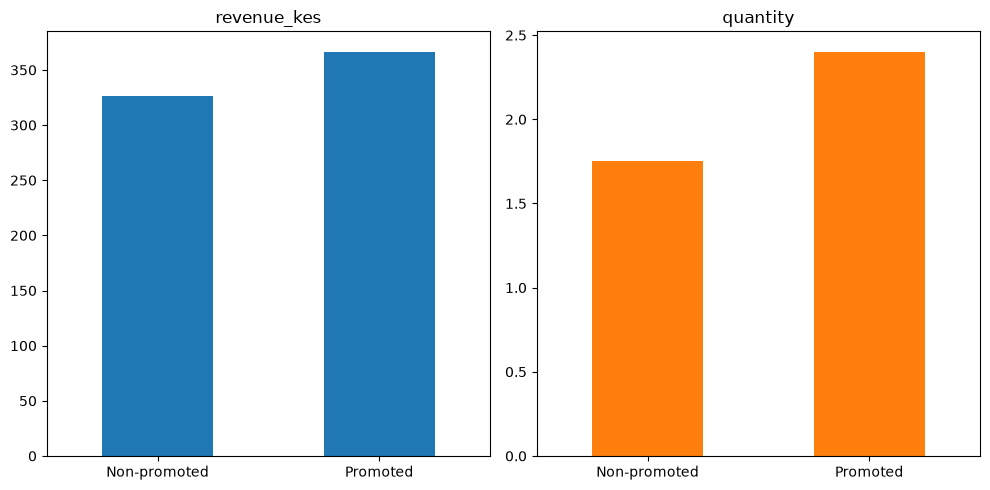

In [35]:
promo_sales = sales.groupby("promo_indicator")[["revenue_kes","quantity"]].mean()
promo_sales.index = ["Non-promoted","Promoted"]
promo_sales.plot(kind = "bar", subplots=True, layout=(1,2), figsize=(10,5), legend=False, rot = 0)
plt.tight_layout()
plt.show()

_Promoted sales are associated with higher quantities sold and higher average revenue per sales line. This suggests that promotions may provide useful information for forecasting demand._

- - Mann whitney U test

In [36]:
# Weekly Promotions
weekly_promo_sales = sales.groupby(
    ["week_start", "store_id", "product_id", "promo_indicator"]).agg(
    units_sold=("quantity", "sum")).reset_index()

In [37]:
# Mannwhitney U test
H0 = "There is no difference in the distribution of weekly units sold between promotional and non-promotional periods."
H1 = "There is a significant difference in the distribution of weekly units sold between promotional and non-promotional periods."
promo = weekly_promo_sales[weekly_promo_sales["promo_indicator"]==1]["units_sold"]
no_promo = weekly_promo_sales[weekly_promo_sales["promo_indicator"]==0]["units_sold"]
p_median = promo.median()
np_median = no_promo.median()
α = 0.05
stat, p = mannwhitneyu(promo, no_promo, alternative = "two-sided")
print(f"Promo_Median: {p_median}")
print(f"Non_Promo Median: {np_median}")
print(f"Test Statistic: {stat}")
print(f"P-Value: {p}")

if p <= α:
    print("Reject the null Hypothersis: There is a significant difference in distribution of weekly units sold between promotional and non-promotional periods")
else:
    print("Fail to reject the null hypothesis: There is no difference in uits sold in either period")

Promo_Median: 20.0
Non_Promo Median: 13.0
Test Statistic: 1795560965.5
P-Value: 0.0
Reject the null Hypothersis: There is a significant difference in distribution of weekly units sold between promotional and non-promotional periods


In [38]:
# effect size to determine practical significance
n1 = len(no_promo)
n2 = len(promo)
rank_biserial = 1 - (2 * stat) / (n1 * n2)
print(f"Effect Size(Rank biserial): {rank_biserial:.3f}")

Effect Size(Rank biserial): -0.183


_Promoted sales are associated with higher quantities sold and higher average revenue per sales line. At weekly store-product level, promotional periods had a higher median of 20 units compared with 13 in non-promotional periods. The Mann-Whitney U test is statistically significant (p < 0.001), but the rank-biserial effect size of -0.18 indicates a small effect. Promotions may still provide useful information for forecasting demand._

- Average Revenue and Quantity across discount levels

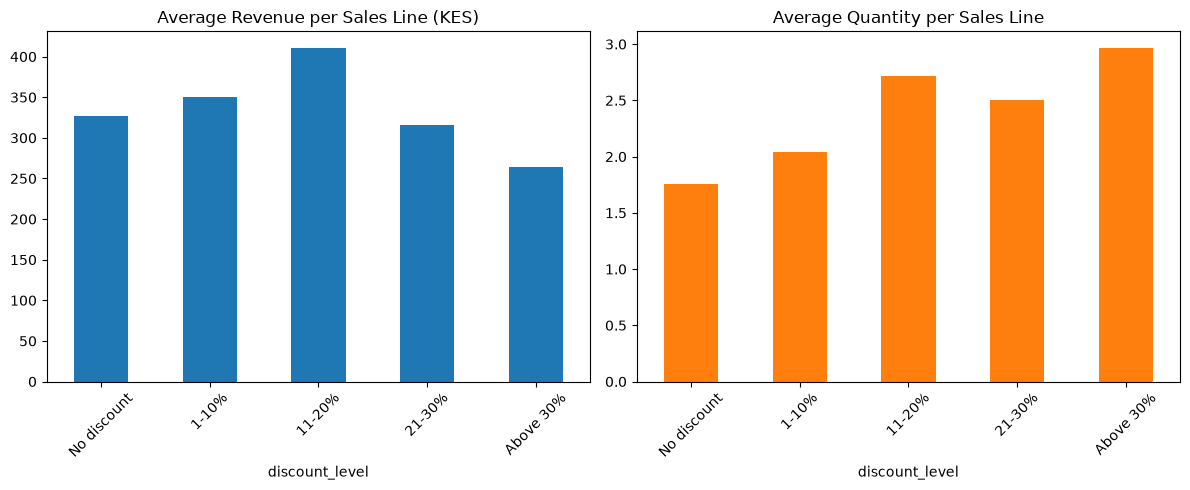

In [39]:
# Compare average revenue and quantity across discount levels

sales["discount_level"] = pd.cut(
    sales["discount_pct"],
    bins=[-1, 0, 10, 20, 30, 100],
    labels=["No discount", "1-10%", "11-20%", "21-30%", "Above 30%"])
discount_sales = sales.groupby("discount_level", observed=False)[
    ["revenue_kes", "quantity"]].mean()
discount_sales.plot(kind="bar", subplots=True, layout=(1, 2), figsize=(12, 5), 
                    legend=False, rot=45,  title=["Average Revenue per Sales Line (KES)", "Average Quantity per Sales Line"])
plt.tight_layout()
plt.show()

In [40]:
sales.to_csv(data + "sales.csv", index=False)

_larger discounts may encourage higher quantities sold, but the additional quantities do not necessarily compensate for the lower selling price._

In [41]:
# Spearman correlation(discount percentage and quantity)
discount_sales = sales[sales["discount_pct"] > 0]

H0 = "There is no significant relationship between discount percentage and units sold."
H1 = "There is a significant relationship between discount percentage and units sold."
α = 0.05
correlation, p = spearmanr(discount_sales["discount_pct"], discount_sales["quantity"])

print(f"Spearman R correlation: {correlation:.3f}")
print("P-value:", p) 

if p <= α:
    print("Reject the null hypothesis: There is a relationship between discount percentage and units sold")
else:
    print("Fail to reject the null Hypothesis: There is no significant relationship between the two")

Spearman R correlation: 0.151
P-value: 0.0
Reject the null hypothesis: There is a relationship between discount percentage and units sold


_Larger discounts may encourage higher quantities sold, but the additional quantities do not necessarily compensate for the lower selling price. Spearman's rank correlation shows a statistically significant positive relationship between discount percentage and units sold (rho = 0.151, p < 0.001), but the correlation is weak. Discount depth alone is not a strong predictor of sales volume._

## 7. Inflation Analysis

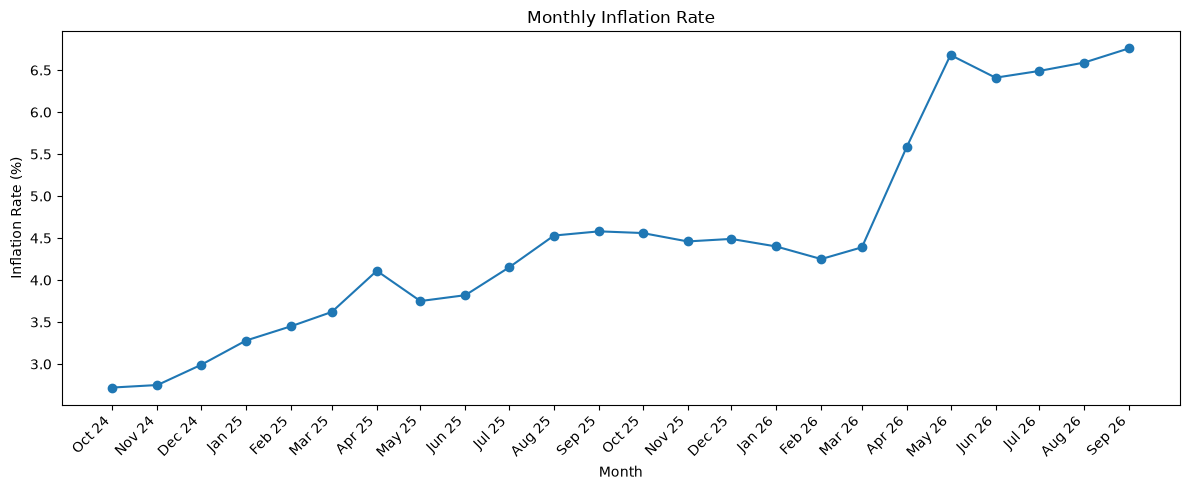

In [42]:
# Inflation trens over the 2 year period
inflation["month"] = pd.to_datetime(inflation["month"])
plt.figure(figsize=(12, 5))
plt.plot(inflation["month"], inflation["inflation_12m_pct"], marker = "o")
plt.title("Monthly Inflation Rate")
plt.xlabel("Month")
plt.ylabel("Inflation Rate (%)")
plt.xticks(inflation["month"], inflation["month"].dt.strftime("%b %y"), rotation=45, ha="right")
plt.tight_layout()
plt.show()

- Monthly Sales and inflation

In [43]:
# merging monthly sales and inflation rate
monthly_sales["month_date"] = pd.to_datetime(dict(year=monthly_sales["year"], month=monthly_sales["month"], day=1))

inflation_by_month = inflation.rename(columns={"month": "month_date"})[["month_date", "inflation_12m_pct"]]
monthly_sales = monthly_sales.merge(inflation_by_month, on="month_date", how="left")

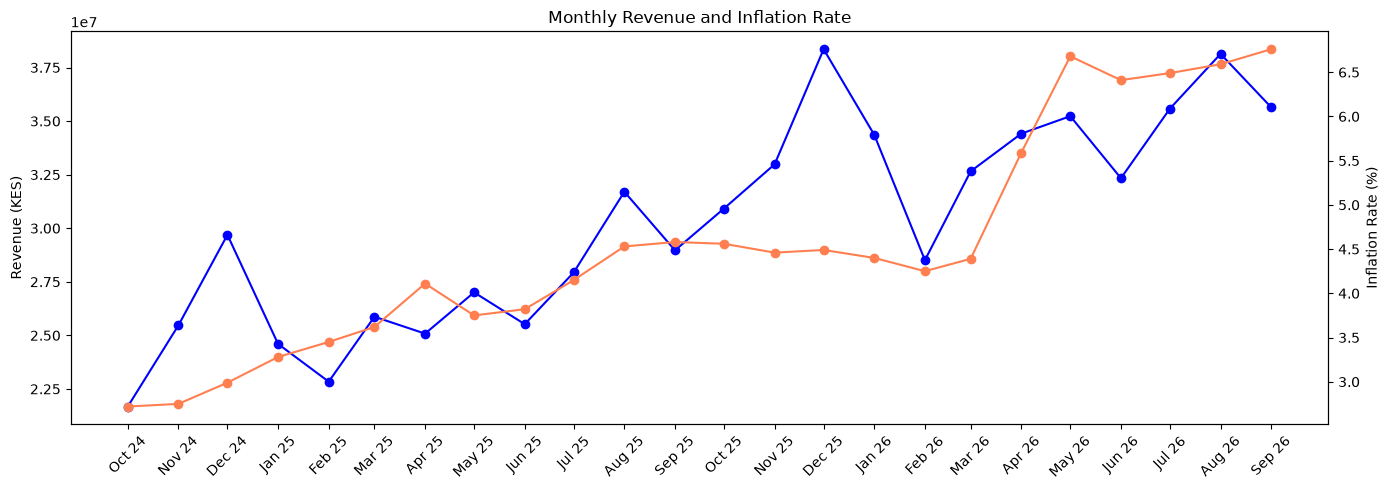

In [44]:
# The visual
fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(monthly_sales["month_date"], monthly_sales["revenue"],marker="o", color="blue", label="Revenue")
ax1.set_ylabel("Revenue (KES)")

ax2 = ax1.twinx()
ax2.plot(monthly_sales["month_date"], monthly_sales["inflation_12m_pct"],marker="o", color="coral", label="Inflation")
ax2.set_ylabel("Inflation Rate (%)")

ax1.set_xticks(monthly_sales["month_date"])
ax1.set_xticklabels(monthly_sales["month_date"].dt.strftime("%b %y"), rotation=45)
plt.title("Monthly Revenue and Inflation Rate")
plt.tight_layout()
plt.show()

- Units sold and inflation

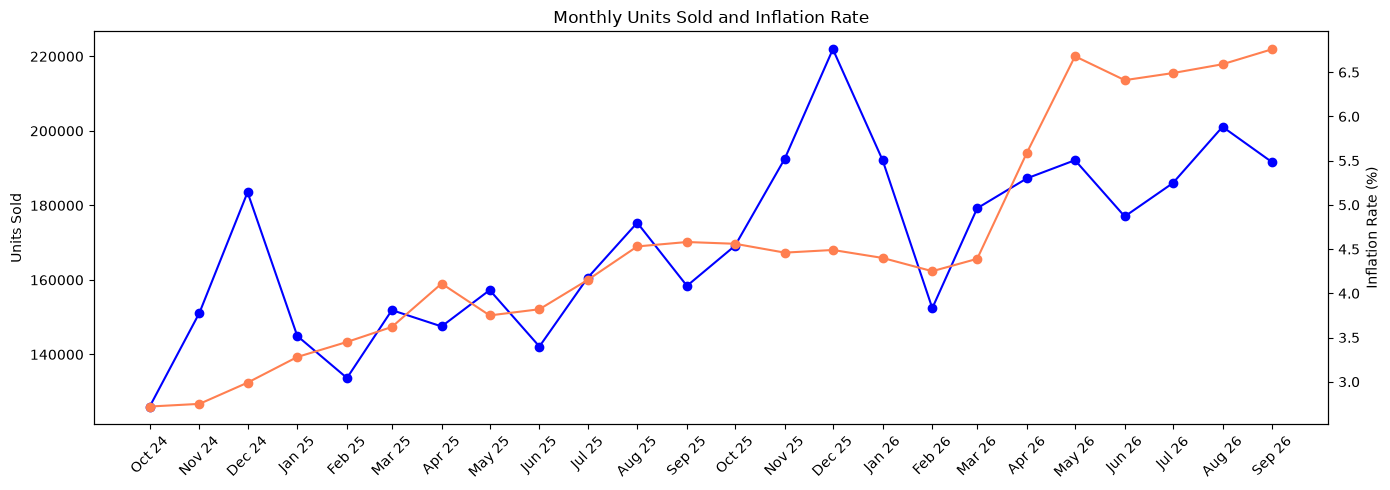

In [45]:
fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(monthly_sales["month_date"], monthly_sales["units_sold"],marker="o", color="blue", label="Units Sold")
ax1.set_ylabel("Units Sold")

ax2 = ax1.twinx()
ax2.plot(monthly_sales["month_date"], monthly_sales["inflation_12m_pct"],
         marker="o", color="coral", label="Inflation")
ax2.set_ylabel("Inflation Rate (%)")

ax1.set_xticks(monthly_sales["month_date"])
ax1.set_xticklabels(monthly_sales["month_date"].dt.strftime("%b %y"), rotation=45)

plt.title("Monthly Units Sold and Inflation Rate")
plt.tight_layout()
plt.show()

In [46]:
# Correlation between the targets and inflation
correlation_with_inflation = monthly_sales[["revenue", "units_sold", "transactions"]].corrwith(
    monthly_sales["inflation_12m_pct"], method = "spearman")
display(correlation_with_inflation.to_frame("Correlation between targts and Inflation"))

,Correlation between targts and Inflation
revenue,0.84
units_sold,0.72
transactions,0.85


_Monthly revenue and units sold generally increased over the period, alongside a rise in the inflation rate. However, the two did not always move in the same direction and higher inflation did not consistently correspond with lower sales. The correlations with inflation are strong, but could reflect the fact that sales and inflation both trended upward over the same period, which makes them look related even when the relationship may not be direct._

## Key EDA Findings

1. Food Staples is the top revenue category in all 10 stores, while Sugar 1kg is the top product by units sold in all 10. Secondary categories and products differ by store, and store revenue varies considerably.

2. Sales volumes grew over the two years, December is the strongest month in both years, and Saturdays (followed by Sundays and Fridays) are the busiest days. Differences between calendar months are statistically significant but small (effect sizes of about 0.04). Public holidays show no significant effect on daily sales.

3. Month-end days have substantially higher revenue and units sold than other days (rank-biserial 0.91, a very large effect), suggesting payday-related spending. Month-end should therefore be considered as a feature in the forecasting model.

4. Promoted weekly store-product sales have a higher median (19 vs. 12 units), but the effect is small (rank-biserial +0.19). Deeper discounts are only weakly associated with higher quantities (rho = 0.15).

5. Average revenue per store is highest in Nairobi (about KES 104M), followed by Machakos (KES 64M), Kajiado (KES 56M) and Kiambu (KES 48M), and lowest in Nakuru (KES 9M). Customers aged 35–44 spend the most per customer (roughly KES 97,000–101,000, compared with KES 60,000–65,000 for ages 18–24).